Step 8: UnivariateCox CoxPH Explainability
This notebook explains the final UnivariateCox CoxPH survival model using its inherent interpretability: regression coefficients, hazard ratios, 95% confidence intervals, statistical significance, and forest plots. The goal is to understand which selected predictors increase or reduce estimated survival hazard.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install lifelines statsmodels -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 8.5 MB/s eta 0:00:00


In [3]:
import os
import pickle
import platform
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import lifelines
import statsmodels

from IPython.display import display
from lifelines.statistics import proportional_hazard_test
from lifelines.utils import concordance_index
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

Reproducibility information

In [4]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("lifelines:", lifelines.__version__)
print("statsmodels:", statsmodels.__version__)
print("Random state:", RANDOM_STATE)

Python: 3.12.13
NumPy: 2.0.2
Pandas: 2.2.2
lifelines: 0.30.3
statsmodels: 0.14.6
Random state: 42


In [5]:
TRAIN_PATH = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/UnivariateCox/hcc_UniCox_train_selected.csv"
TEST_PATH = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/UnivariateCox/hcc_UniCox_test_selected.csv"
MODEL_PATH = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/UnivariateCox/hcc_UniCox_coxph_model.pkl"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"

SIGNIFICANCE_LEVEL = 0.05
TOP_N_FOREST = 20
TOP_N_PATIENT_CONTRIBUTORS = 15

Load selected data and CoxPH model

In [6]:
train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

with open(MODEL_PATH, "rb") as file:
    cph_final = pickle.load(file)

train_data.shape, test_data.shape, cph_final

((1085, 52),
 (272, 52),
 <lifelines.CoxPHFitter: fitted with 1085 total observations, 444 right-censored observations>)

Basic data checks

In [7]:
print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

print("\nTrain missing values:", int(train_data.isna().sum().sum()))
print("Test missing values:", int(test_data.isna().sum().sum()))

print("\nTrain OS_EVENT distribution:")
print(train_data[EVENT_COL].value_counts())

print("\nTest OS_EVENT distribution:")
print(test_data[EVENT_COL].value_counts())

Train shape: (1085, 52)
Test shape: (272, 52)

Train missing values: 0
Test missing values: 0

Train OS_EVENT distribution:
OS_EVENT
1    641
0    444
Name: count, dtype: int64

Test OS_EVENT distribution:
OS_EVENT
1    161
0    111
Name: count, dtype: int64


ID leakage guard

In [8]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"
    assert id_col not in test_data.columns, f"{id_col} found in test_data"

print("ID leakage guard passed.")

ID leakage guard passed.


Selected feature list

In [9]:
feature_columns = [
    col for col in train_data.columns
    if col not in [DURATION_COL, EVENT_COL]
]

print("Number of selected predictors:", len(feature_columns))
feature_columns

Number of selected predictors: 50


['METASTASIS_Yes',
 'CURATIVE_INTENT_SURGERY_Yes',
 'CURATIVE_INTENT_SURGERY_No',
 'METASTASIS_No',
 'MAJOR_LIVER_RESECTION_',
 'RESECTION_MARGIN_',
 'RESECTION_MARGIN_R0',
 'C_N_Yes',
 'PNI_',
 'LVI_',
 'C_N_No',
 'PALLIATIVE_SYSTEMIC_THERPAY_Yes',
 'PNI_No',
 'PALLIATIVE_SYSTEMIC_THERPAY_No',
 'MAJOR_LIVER_RESECTION_No',
 'MULTIFOCAL_DISEASE_Yes',
 'MULTIFOCAL_DISEASE_No',
 'LVI_No',
 'P_N_Negative',
 'ADJUVANT_SYSTEMIC_THERAPY_No',
 'ADJUVANT_SYSTEMIC_THERAPY_Yes',
 'MAJOR_LIVER_RESECTION_Yes',
 'P_N_',
 'CNA_CDKN2A',
 'CNA_TP53',
 'CNA_CDKN2Ap14ARF',
 'CNA_CDKN2Ap16INK4A',
 'LVI_Yes',
 'TUMOR_SIZE',
 'PRED_CATEGORY_Biliary class',
 'CNA_CDKN2B',
 'HISTO_SUBTYPE_',
 'CNA_PPP2R1A',
 'CNA_POLD1',
 'METASTATIC_SITE_Liver',
 'PNI_Yes',
 'MUT_CD276',
 'CNA_WHSC1L1',
 'MUT_ARID1A',
 'DIAGNOSIS_AGE',
 'CNA_HOXB13',
 'CNA_AXL',
 'TUMOR_STAGE_Poorly differentiated',
 'TUMOR_STAGE_Well differentiated',
 'MUT_SHQ1',
 'CNA_XPO1',
 'CNA_REL',
 'MUT_KRAS',
 'NEOADJUVANT_SYSTEMIC_THERAPY_No',
 'MU

Test-set C-index check
This confirms that the loaded CoxPH model matches the final model used in evaluation.

In [10]:
test_risk_scores = cph_final.predict_partial_hazard(test_data)

test_c_index = concordance_index(
    test_data[DURATION_COL],
    -test_risk_scores,
    test_data[EVENT_COL]
)

print(f"Test Concordance Index: {test_c_index:.4f}")

Test Concordance Index: 0.7253


Helper functions for readable interpretation

In [11]:
def classify_feature(feature_name):
    if feature_name.startswith("MUT_"):
        return "Mutation"
    if feature_name.startswith("CNA_"):
        return "Copy number alteration"
    if any(key in feature_name for key in ["SURGERY", "THERAPY", "RESECTION_MARGIN"]):
        return "Treatment / surgery"
    if any(key in feature_name for key in ["METASTASIS", "TUMOR", "LVI", "PNI", "P_N", "C_N", "STAGE", "SITE", "MULTIFOCAL"]):
        return "Clinical / pathology"
    if any(key in feature_name for key in ["AGE", "BMI", "ETHNICITY"]):
        return "Demographic"
    if "GENE_PANEL" in feature_name or "SAMPLE" in feature_name:
        return "Sequencing / sample"
    return "Other"


def readable_label(feature_name):
    if feature_name.startswith("MUT_"):
        return feature_name.replace("MUT_", "") + " mutation"
    if feature_name.startswith("CNA_"):
        return feature_name.replace("CNA_", "") + " CNA"
    return feature_name.replace("_", " ")


def risk_direction(coef_value):
    if coef_value > 0:
        return "Risk-increasing"
    if coef_value < 0:
        return "Protective"
    return "Neutral"


def gene_symbol(feature_name):
    if feature_name.startswith("MUT_"):
        return feature_name.replace("MUT_", "")
    if feature_name.startswith("CNA_"):
        return feature_name.replace("CNA_", "")
    return np.nan

CoxPH model summary
CoxPH explainability comes directly from the fitted coefficients. Positive coefficients increase estimated hazard; negative coefficients reduce estimated hazard.

In [12]:
cox_summary = cph_final.summary.copy()

cox_summary.head()

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
METASTASIS_Yes,0.310608,1.364254,0.144748,0.026907,0.594308,1.027272,1.811777,0.0,2.145853,0.031885,4.970990
CURATIVE_INTENT_SURGERY_Yes,-0.194490,0.823254,0.168934,-0.525595,0.136614,0.591204,1.146386,0.0,-1.151280,0.249617,2.002211
CURATIVE_INTENT_SURGERY_No,0.165897,1.180452,0.168383,-0.164128,0.495922,0.848634,1.642012,0.0,0.985237,0.324508,1.623676
METASTASIS_No,-0.130423,0.877724,0.143965,-0.412589,0.151742,0.661935,1.163860,0.0,-0.905938,0.364969,1.454155
MAJOR_LIVER_RESECTION_,0.047134,1.048263,0.171140,-0.288294,0.382563,0.749541,1.466037,0.0,0.275414,0.782998,0.352919


Build clean explainability table

In [13]:
explainability_df = cox_summary[[
    "coef",
    "exp(coef)",
    "coef lower 95%",
    "coef upper 95%",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p"
]].copy()

explainability_df = explainability_df.rename(columns={
    "coef": "coefficient",
    "exp(coef)": "hazard_ratio",
    "coef lower 95%": "coef_lower_95",
    "coef upper 95%": "coef_upper_95",
    "exp(coef) lower 95%": "hr_lower_95",
    "exp(coef) upper 95%": "hr_upper_95",
    "p": "p_value"
})

explainability_df = explainability_df.reset_index().rename(columns={"covariate": "feature"})
explainability_df["readable_label"] = explainability_df["feature"].apply(readable_label)
explainability_df["feature_group"] = explainability_df["feature"].apply(classify_feature)
explainability_df["gene_symbol"] = explainability_df["feature"].apply(gene_symbol)
explainability_df["direction"] = explainability_df["coefficient"].apply(risk_direction)
explainability_df["abs_coefficient"] = explainability_df["coefficient"].abs()

explainability_df = explainability_df.sort_values("p_value").reset_index(drop=True)

explainability_df.head(20)

,feature,coefficient,hazard_ratio,coef_lower_95,coef_upper_95,hr_lower_95,hr_upper_95,p_value,readable_label,feature_group,gene_symbol,direction,abs_coefficient
0,CNA_TP53,-1.242123,0.288770,-1.770631,-0.713615,0.170226,0.489870,0.000004,TP53 CNA,Copy number alteration,TP53,Protective,1.242123
1,CNA_AXL,1.796440,6.028150,0.934753,2.658128,2.546584,14.269545,0.000044,AXL CNA,Copy number alteration,AXL,Risk-increasing,1.796440
2,MUT_SHQ1,1.576031,4.835724,0.657081,2.494981,1.929153,12.121499,0.000775,SHQ1 mutation,Mutation,SHQ1,Risk-increasing,1.576031
3,DIAGNOSIS_AGE,0.010732,1.010790,0.004092,0.017372,1.004101,1.017523,0.001535,DIAGNOSIS AGE,Demographic,NaN,Risk-increasing,0.010732
4,CNA_POLD1,5.000000,148.413157,1.901028,8.098972,6.692768,3291.084490,0.001565,POLD1 CNA,Copy number alteration,POLD1,Risk-increasing,5.000000
5,CNA_PPP2R1A,5.000000,148.413157,1.901028,8.098972,6.692768,3291.084490,0.001565,PPP2R1A CNA,Copy number alteration,PPP2R1A,Risk-increasing,5.000000
6,MUT_CD276,2.419085,11.235573,0.845939,3.992231,2.330165,54.175612,0.002579,CD276 mutation,Mutation,CD276,Risk-increasing,2.419085
7,MUT_FGFR4,1.732219,5.653183,0.501061,2.963377,1.650471,19.363245,0.005822,FGFR4 mutation,Mutation,FGFR4,Risk-increasing,1.732219
8,CNA_HOXB13,1.070315,2.916299,0.307265,1.833366,1.359701,6.254903,0.005974,HOXB13 CNA,Copy number alteration,HOXB13,Risk-increasing,1.070315
9,PRED_CATEGORY_Biliary class,0.395991,1.485856,0.053359,0.738624,1.054808,2.093053,0.023501,PRED CATEGORY Biliary class,Other,NaN,Risk-increasing,0.395991


Add multiple-testing adjusted p-values
The raw CoxPH p-value is useful, but we also compute Benjamini-Hochberg adjusted p-values because many predictors are being reviewed together.

In [14]:
explainability_df["bh_adjusted_p"] = multipletests(
    explainability_df["p_value"],
    method="fdr_bh"
)[1]

explainability_df[[
    "feature",
    "feature_group",
    "coefficient",
    "hazard_ratio",
    "hr_lower_95",
    "hr_upper_95",
    "p_value",
    "bh_adjusted_p",
    "direction"
]].head(20)

,feature,feature_group,coefficient,hazard_ratio,hr_lower_95,hr_upper_95,p_value,bh_adjusted_p,direction
0,CNA_TP53,Copy number alteration,-1.242123,0.288770,0.170226,0.489870,0.000004,0.000205,Protective
1,CNA_AXL,Copy number alteration,1.796440,6.028150,2.546584,14.269545,0.000044,0.001097,Risk-increasing
2,MUT_SHQ1,Mutation,1.576031,4.835724,1.929153,12.121499,0.000775,0.012924,Risk-increasing
3,DIAGNOSIS_AGE,Demographic,0.010732,1.010790,1.004101,1.017523,0.001535,0.013045,Risk-increasing
4,CNA_POLD1,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,0.013045,Risk-increasing
5,CNA_PPP2R1A,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,0.013045,Risk-increasing
6,MUT_CD276,Mutation,2.419085,11.235573,2.330165,54.175612,0.002579,0.018422,Risk-increasing
7,MUT_FGFR4,Mutation,1.732219,5.653183,1.650471,19.363245,0.005822,0.033189,Risk-increasing
8,CNA_HOXB13,Copy number alteration,1.070315,2.916299,1.359701,6.254903,0.005974,0.033189,Risk-increasing
9,PRED_CATEGORY_Biliary class,Other,0.395991,1.485856,1.054808,2.093053,0.023501,0.117504,Risk-increasing


Significant predictors
Predictors are considered significant here using raw p < 0.05. The adjusted p-value column is shown as an additional rigor check.

In [15]:
significant_predictors = explainability_df[
    explainability_df["p_value"] < SIGNIFICANCE_LEVEL
].copy()

print("Number of significant predictors:", significant_predictors.shape[0])

significant_predictors[[
    "feature",
    "readable_label",
    "feature_group",
    "coefficient",
    "hazard_ratio",
    "hr_lower_95",
    "hr_upper_95",
    "p_value",
    "bh_adjusted_p",
    "direction"
]]

Number of significant predictors: 13


,feature,readable_label,feature_group,coefficient,hazard_ratio,hr_lower_95,hr_upper_95,p_value,bh_adjusted_p,direction
0,CNA_TP53,TP53 CNA,Copy number alteration,-1.242123,0.288770,0.170226,0.489870,0.000004,0.000205,Protective
1,CNA_AXL,AXL CNA,Copy number alteration,1.796440,6.028150,2.546584,14.269545,0.000044,0.001097,Risk-increasing
2,MUT_SHQ1,SHQ1 mutation,Mutation,1.576031,4.835724,1.929153,12.121499,0.000775,0.012924,Risk-increasing
3,DIAGNOSIS_AGE,DIAGNOSIS AGE,Demographic,0.010732,1.010790,1.004101,1.017523,0.001535,0.013045,Risk-increasing
4,CNA_POLD1,POLD1 CNA,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,0.013045,Risk-increasing
5,CNA_PPP2R1A,PPP2R1A CNA,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,0.013045,Risk-increasing
6,MUT_CD276,CD276 mutation,Mutation,2.419085,11.235573,2.330165,54.175612,0.002579,0.018422,Risk-increasing
7,MUT_FGFR4,FGFR4 mutation,Mutation,1.732219,5.653183,1.650471,19.363245,0.005822,0.033189,Risk-increasing
8,CNA_HOXB13,HOXB13 CNA,Copy number alteration,1.070315,2.916299,1.359701,6.254903,0.005974,0.033189,Risk-increasing
9,PRED_CATEGORY_Biliary class,PRED CATEGORY Biliary class,Other,0.395991,1.485856,1.054808,2.093053,0.023501,0.117504,Risk-increasing


Risk-increasing predictors
These predictors have positive coefficients and hazard ratio greater than 1. They push the CoxPH model toward higher estimated hazard.

In [16]:
risk_increasing_predictors = significant_predictors[
    significant_predictors["coefficient"] > 0
].sort_values("hazard_ratio", ascending=False)

risk_increasing_predictors[[
    "feature",
    "readable_label",
    "feature_group",
    "coefficient",
    "hazard_ratio",
    "hr_lower_95",
    "hr_upper_95",
    "p_value",
    "direction"
]]

,feature,readable_label,feature_group,coefficient,hazard_ratio,hr_lower_95,hr_upper_95,p_value,direction
4,CNA_POLD1,POLD1 CNA,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing
5,CNA_PPP2R1A,PPP2R1A CNA,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing
6,MUT_CD276,CD276 mutation,Mutation,2.419085,11.235573,2.330165,54.175612,0.002579,Risk-increasing
1,CNA_AXL,AXL CNA,Copy number alteration,1.796440,6.028150,2.546584,14.269545,0.000044,Risk-increasing
7,MUT_FGFR4,FGFR4 mutation,Mutation,1.732219,5.653183,1.650471,19.363245,0.005822,Risk-increasing
2,MUT_SHQ1,SHQ1 mutation,Mutation,1.576031,4.835724,1.929153,12.121499,0.000775,Risk-increasing
8,CNA_HOXB13,HOXB13 CNA,Copy number alteration,1.070315,2.916299,1.359701,6.254903,0.005974,Risk-increasing
9,PRED_CATEGORY_Biliary class,PRED CATEGORY Biliary class,Other,0.395991,1.485856,1.054808,2.093053,0.023501,Risk-increasing
11,METASTASIS_Yes,METASTASIS Yes,Clinical / pathology,0.310608,1.364254,1.027272,1.811777,0.031885,Risk-increasing
10,MUT_KRAS,KRAS mutation,Mutation,0.265757,1.304418,1.026229,1.658018,0.029892,Risk-increasing


Protective predictors
These predictors have negative coefficients and hazard ratio less than 1. They push the CoxPH model toward lower estimated hazard.

In [17]:
protective_predictors = significant_predictors[
    significant_predictors["coefficient"] < 0
].sort_values("hazard_ratio", ascending=True)

protective_predictors[[
    "feature",
    "readable_label",
    "feature_group",
    "coefficient",
    "hazard_ratio",
    "hr_lower_95",
    "hr_upper_95",
    "p_value",
    "direction"
]]

,feature,readable_label,feature_group,coefficient,hazard_ratio,hr_lower_95,hr_upper_95,p_value,direction
0,CNA_TP53,TP53 CNA,Copy number alteration,-1.242123,0.288770,0.170226,0.489870,0.000004,Protective
12,P_N_Negative,P N Negative,Clinical / pathology,-0.219258,0.803115,0.647818,0.995641,0.045520,Protective


Forest plot of significant predictors
The forest plot shows hazard ratios with 95% confidence intervals. The vertical line at HR = 1 separates risk-increasing and protective directions.

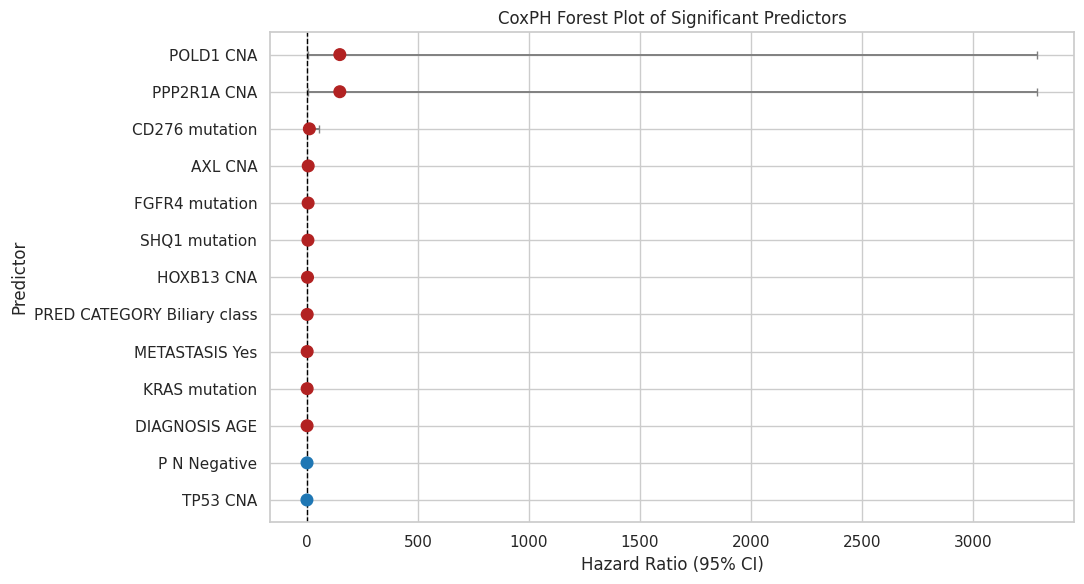

In [18]:
forest_df = significant_predictors.copy()

if forest_df.shape[0] > TOP_N_FOREST:
    forest_df = forest_df.sort_values("p_value").head(TOP_N_FOREST)

forest_df = forest_df.sort_values("hazard_ratio", ascending=True).reset_index(drop=True)
forest_df["plot_label"] = forest_df["readable_label"]
forest_df["color"] = np.where(forest_df["coefficient"] > 0, "#B22222", "#1F77B4")

plt.figure(figsize=(11, max(6, 0.42 * forest_df.shape[0])))

plt.errorbar(
    forest_df["hazard_ratio"],
    np.arange(forest_df.shape[0]),
    xerr=[
        forest_df["hazard_ratio"] - forest_df["hr_lower_95"],
        forest_df["hr_upper_95"] - forest_df["hazard_ratio"]
    ],
    fmt="none",
    ecolor="gray",
    elinewidth=1.4,
    capsize=3
)

plt.scatter(
    forest_df["hazard_ratio"],
    np.arange(forest_df.shape[0]),
    c=forest_df["color"],
    s=70,
    zorder=3
)

plt.axvline(1.0, color="black", linestyle="--", linewidth=1)
plt.yticks(np.arange(forest_df.shape[0]), forest_df["plot_label"])
plt.xlabel("Hazard Ratio (95% CI)")
plt.ylabel("Predictor")
plt.title("CoxPH Forest Plot of Significant Predictors")
plt.tight_layout()
plt.show()

Gene-derived CoxPH predictors
This filters the CoxPH explanation to mutation and copy-number features only. These are the features that can support later candidate prognostic gene discussion.

In [19]:
gene_predictors = explainability_df[
    explainability_df["feature"].str.startswith(("MUT_", "CNA_"))
].copy()

print("Number of gene-derived predictors:", gene_predictors.shape[0])

gene_predictors[[
    "feature",
    "gene_symbol",
    "feature_group",
    "coefficient",
    "hazard_ratio",
    "hr_lower_95",
    "hr_upper_95",
    "p_value",
    "bh_adjusted_p",
    "direction"
]].sort_values("p_value")

Number of gene-derived predictors: 17


,feature,gene_symbol,feature_group,coefficient,hazard_ratio,hr_lower_95,hr_upper_95,p_value,bh_adjusted_p,direction
0,CNA_TP53,TP53,Copy number alteration,-1.242123,0.288770,0.170226,0.489870,0.000004,0.000205,Protective
1,CNA_AXL,AXL,Copy number alteration,1.796440,6.028150,2.546584,14.269545,0.000044,0.001097,Risk-increasing
2,MUT_SHQ1,SHQ1,Mutation,1.576031,4.835724,1.929153,12.121499,0.000775,0.012924,Risk-increasing
4,CNA_POLD1,POLD1,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,0.013045,Risk-increasing
5,CNA_PPP2R1A,PPP2R1A,Copy number alteration,5.000000,148.413157,6.692768,3291.084490,0.001565,0.013045,Risk-increasing
6,MUT_CD276,CD276,Mutation,2.419085,11.235573,2.330165,54.175612,0.002579,0.018422,Risk-increasing
7,MUT_FGFR4,FGFR4,Mutation,1.732219,5.653183,1.650471,19.363245,0.005822,0.033189,Risk-increasing
8,CNA_HOXB13,HOXB13,Copy number alteration,1.070315,2.916299,1.359701,6.254903,0.005974,0.033189,Risk-increasing
10,MUT_KRAS,KRAS,Mutation,0.265757,1.304418,1.026229,1.658018,0.029892,0.132853,Risk-increasing
15,CNA_WHSC1L1,WHSC1L1,Copy number alteration,-0.489005,0.613236,0.355978,1.056411,0.078035,0.243859,Protective


Significant gene-derived predictors

In [20]:
significant_gene_predictors = gene_predictors[
    gene_predictors["p_value"] < SIGNIFICANCE_LEVEL
].sort_values("p_value")

print("Number of significant gene-derived predictors:", significant_gene_predictors.shape[0])

significant_gene_predictors[[
    "feature",
    "gene_symbol",
    "coefficient",
    "hazard_ratio",
    "hr_lower_95",
    "hr_upper_95",
    "p_value",
    "direction"
]]

Number of significant gene-derived predictors: 9


,feature,gene_symbol,coefficient,hazard_ratio,hr_lower_95,hr_upper_95,p_value,direction
0,CNA_TP53,TP53,-1.242123,0.288770,0.170226,0.489870,0.000004,Protective
1,CNA_AXL,AXL,1.796440,6.028150,2.546584,14.269545,0.000044,Risk-increasing
2,MUT_SHQ1,SHQ1,1.576031,4.835724,1.929153,12.121499,0.000775,Risk-increasing
4,CNA_POLD1,POLD1,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing
5,CNA_PPP2R1A,PPP2R1A,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing
6,MUT_CD276,CD276,2.419085,11.235573,2.330165,54.175612,0.002579,Risk-increasing
7,MUT_FGFR4,FGFR4,1.732219,5.653183,1.650471,19.363245,0.005822,Risk-increasing
8,CNA_HOXB13,HOXB13,1.070315,2.916299,1.359701,6.254903,0.005974,Risk-increasing
10,MUT_KRAS,KRAS,0.265757,1.304418,1.026229,1.658018,0.029892,Risk-increasing


Feature-group summary
This shows whether significant CoxPH signals are mostly clinical, treatment-related, or gene-derived.

In [21]:
group_summary = (
    significant_predictors
    .groupby(["feature_group", "direction"])
    .size()
    .reset_index(name="count")
    .sort_values(["feature_group", "direction"])
)

group_summary

,feature_group,direction,count
0,Clinical / pathology,Protective,1
1,Clinical / pathology,Risk-increasing,1
2,Copy number alteration,Protective,1
3,Copy number alteration,Risk-increasing,4
4,Demographic,Risk-increasing,1
5,Mutation,Risk-increasing,4
6,Other,Risk-increasing,1


Proportional hazards diagnostic
This diagnostic checks whether predictors show evidence against the proportional hazards assumption. If some predictors are flagged, we report it as a model limitation rather than changing the final baseline model here.

In [22]:
try:
    ph_results = proportional_hazard_test(
        cph_final,
        train_data,
        time_transform="rank"
    )

    ph_summary = ph_results.summary.reset_index().rename(columns={"index": "feature"})
    ph_summary = ph_summary.sort_values("p")
    ph_summary["violates_ph_at_0_05"] = ph_summary["p"] < 0.05

    print("Predictors flagged at p < 0.05:", int(ph_summary["violates_ph_at_0_05"].sum()))
    ph_summary.head(20)

except Exception as error:
    print("Proportional hazards diagnostic could not be completed.")
    print("Reason:", error)

Predictors flagged at p < 0.05: 2


Patient-level CoxPH contribution setup
For CoxPH, an individual patient's linear predictor is the sum of feature values multiplied by CoxPH coefficients. Large positive contributions push risk upward, while large negative contributions push risk downward.

In [23]:
test_linear_predictor = cph_final.predict_log_partial_hazard(test_data)

patient_risk_df = test_data[[DURATION_COL, EVENT_COL]].copy()
patient_risk_df["linear_risk_score"] = test_linear_predictor.values
patient_risk_df["partial_hazard"] = test_risk_scores.values

high_risk_index = patient_risk_df["linear_risk_score"].idxmax()
low_risk_index = patient_risk_df["linear_risk_score"].idxmin()
median_risk_index = (
    patient_risk_df["linear_risk_score"]
    .sub(patient_risk_df["linear_risk_score"].median())
    .abs()
    .idxmin()
)

representative_patients = pd.DataFrame([
    {"patient_type": "Highest predicted risk", "test_index": high_risk_index},
    {"patient_type": "Lowest predicted risk", "test_index": low_risk_index},
    {"patient_type": "Median predicted risk", "test_index": median_risk_index},
])

representative_patients = representative_patients.merge(
    patient_risk_df.reset_index().rename(columns={"index": "test_index"}),
    on="test_index",
    how="left"
)

representative_patients

,patient_type,test_index,OS_MONTHS,OS_EVENT,linear_risk_score,partial_hazard
0,Highest predicted risk,90,17.148,0,2.586674,1.328551e+01
1,Lowest predicted risk,80,6.144,1,-20.670492,1.054191e-09
2,Median predicted risk,122,5.556,1,0.055222,1.056776e+00


Patient-level contribution table

In [24]:
coef_series = cph_final.params_.copy()

def patient_contributions(row_index, top_n=15):
    feature_values = test_data.loc[row_index, coef_series.index]
    contribution_df = pd.DataFrame({
        "feature": coef_series.index,
        "feature_value": feature_values.values,
        "coefficient": coef_series.values,
    })

    contribution_df["contribution"] = (
        contribution_df["feature_value"] * contribution_df["coefficient"]
    )
    contribution_df["absolute_contribution"] = contribution_df["contribution"].abs()
    contribution_df["readable_label"] = contribution_df["feature"].apply(readable_label)
    contribution_df["direction"] = contribution_df["contribution"].apply(risk_direction)

    return contribution_df.sort_values(
        "absolute_contribution",
        ascending=False
    ).head(top_n)


for _, patient in representative_patients.iterrows():
    print("\n" + "=" * 80)
    print(patient["patient_type"])
    print("Test index:", int(patient["test_index"]))
    print("OS_MONTHS:", round(patient[DURATION_COL], 3))
    print("OS_EVENT:", int(patient[EVENT_COL]))
    print("Linear risk score:", round(patient["linear_risk_score"], 4))
    display(patient_contributions(int(patient["test_index"]), TOP_N_PATIENT_CONTRIBUTORS))


Highest predicted risk
Test index: 90
OS_MONTHS: 17.148
OS_EVENT: 0
Linear risk score: 2.5867


,feature,feature_value,coefficient,contribution,absolute_contribution,readable_label,direction
36,MUT_CD276,1.0,2.419085,2.419085,2.419085,CD276 mutation,Risk-increasing
39,DIAGNOSIS_AGE,58.0,0.010732,0.622457,0.622457,DIAGNOSIS AGE,Risk-increasing
28,TUMOR_SIZE,11.5,0.021286,0.244784,0.244784,TUMOR SIZE,Risk-increasing
2,CURATIVE_INTENT_SURGERY_No,1.0,0.165897,0.165897,0.165897,CURATIVE INTENT SURGERY No,Risk-increasing
11,PALLIATIVE_SYSTEMIC_THERPAY_Yes,1.0,0.165642,0.165642,0.165642,PALLIATIVE SYSTEMIC THERPAY Yes,Risk-increasing
42,TUMOR_STAGE_Poorly differentiated,1.0,0.130904,0.130904,0.130904,TUMOR STAGE Poorly differentiated,Risk-increasing
3,METASTASIS_No,1.0,-0.130423,-0.130423,0.130423,METASTASIS No,Protective
19,ADJUVANT_SYSTEMIC_THERAPY_No,1.0,0.119991,0.119991,0.119991,ADJUVANT SYSTEMIC THERAPY No,Risk-increasing
48,NEOADJUVANT_SYSTEMIC_THERAPY_No,1.0,0.079493,0.079493,0.079493,NEOADJUVANT SYSTEMIC THERAPY No,Risk-increasing
9,LVI_,1.0,-0.077906,-0.077906,0.077906,LVI,Protective



Lowest predicted risk
Test index: 80
OS_MONTHS: 6.144
OS_EVENT: 1
Linear risk score: -20.6705


,feature,feature_value,coefficient,contribution,absolute_contribution,readable_label,direction
32,CNA_PPP2R1A,-2.0,5.000000,-10.000000,10.000000,PPP2R1A CNA,Protective
33,CNA_POLD1,-2.0,5.000000,-10.000000,10.000000,POLD1 CNA,Protective
39,DIAGNOSIS_AGE,44.0,0.010732,0.472209,0.472209,DIAGNOSIS AGE,Risk-increasing
28,TUMOR_SIZE,10.7,0.021286,0.227756,0.227756,TUMOR SIZE,Risk-increasing
18,P_N_Negative,1.0,-0.219258,-0.219258,0.219258,P N Negative,Protective
2,CURATIVE_INTENT_SURGERY_No,1.0,0.165897,0.165897,0.165897,CURATIVE INTENT SURGERY No,Risk-increasing
3,METASTASIS_No,1.0,-0.130423,-0.130423,0.130423,METASTASIS No,Protective
9,LVI_,1.0,-0.077906,-0.077906,0.077906,LVI,Protective
10,C_N_No,1.0,-0.062433,-0.062433,0.062433,C N No,Protective
15,MULTIFOCAL_DISEASE_Yes,1.0,0.057612,0.057612,0.057612,MULTIFOCAL DISEASE Yes,Risk-increasing



Median predicted risk
Test index: 122
OS_MONTHS: 5.556
OS_EVENT: 1
Linear risk score: 0.0552


,feature,feature_value,coefficient,contribution,absolute_contribution,readable_label,direction
39,DIAGNOSIS_AGE,77.0,0.010732,0.826365,0.826365,DIAGNOSIS AGE,Risk-increasing
18,P_N_Negative,1.0,-0.219258,-0.219258,0.219258,P N Negative,Protective
2,CURATIVE_INTENT_SURGERY_No,1.0,0.165897,0.165897,0.165897,CURATIVE INTENT SURGERY No,Risk-increasing
11,PALLIATIVE_SYSTEMIC_THERPAY_Yes,1.0,0.165642,0.165642,0.165642,PALLIATIVE SYSTEMIC THERPAY Yes,Risk-increasing
28,TUMOR_SIZE,7.0,0.021286,0.148999,0.148999,TUMOR SIZE,Risk-increasing
42,TUMOR_STAGE_Poorly differentiated,1.0,0.130904,0.130904,0.130904,TUMOR STAGE Poorly differentiated,Risk-increasing
3,METASTASIS_No,1.0,-0.130423,-0.130423,0.130423,METASTASIS No,Protective
19,ADJUVANT_SYSTEMIC_THERAPY_No,1.0,0.119991,0.119991,0.119991,ADJUVANT SYSTEMIC THERAPY No,Risk-increasing
48,NEOADJUVANT_SYSTEMIC_THERAPY_No,1.0,0.079493,0.079493,0.079493,NEOADJUVANT SYSTEMIC THERAPY No,Risk-increasing
9,LVI_,1.0,-0.077906,-0.077906,0.077906,LVI,Protective


Patient-level contribution waterfall plots

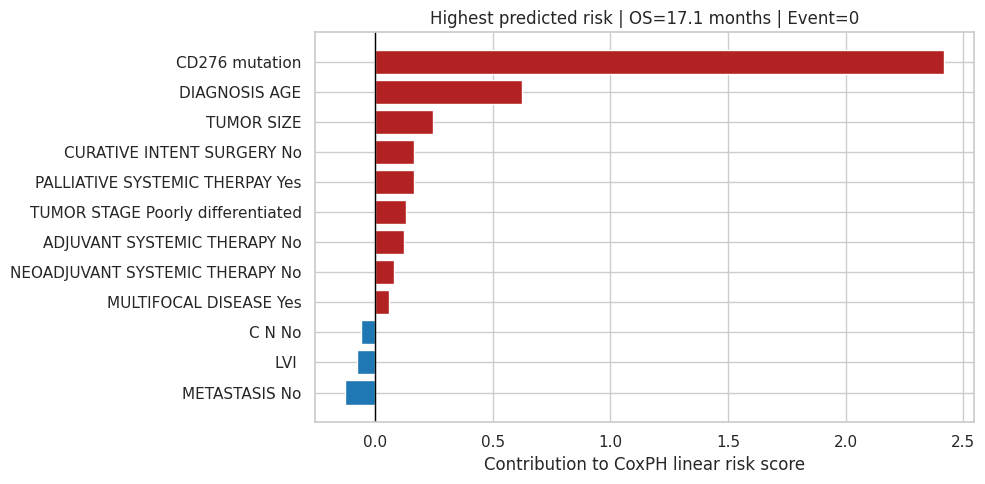

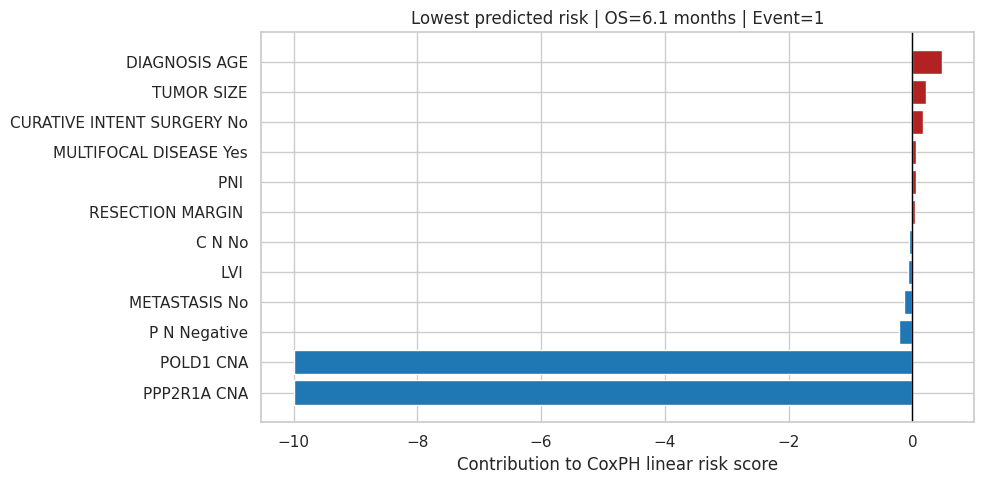

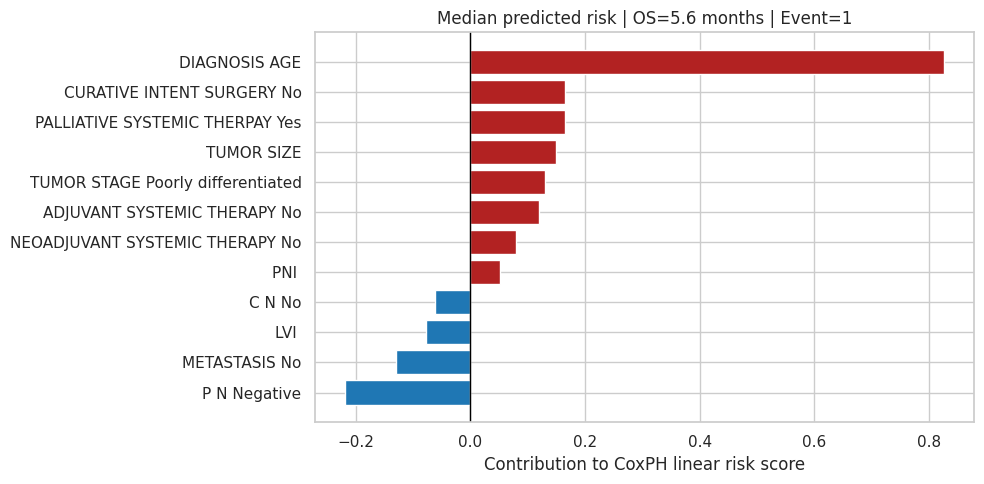

In [25]:
def plot_patient_waterfall(row_index, patient_label, top_n=12):
    contribution_df = patient_contributions(row_index, top_n=top_n).sort_values("contribution")

    colors = np.where(contribution_df["contribution"] > 0, "#B22222", "#1F77B4")

    plt.figure(figsize=(10, max(5, 0.38 * contribution_df.shape[0])))
    plt.barh(
        contribution_df["readable_label"],
        contribution_df["contribution"],
        color=colors
    )
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Contribution to CoxPH linear risk score")
    plt.title(patient_label)
    plt.tight_layout()
    plt.show()


for _, patient in representative_patients.iterrows():
    label = (
        f"{patient['patient_type']} | "
        f"OS={patient[DURATION_COL]:.1f} months | "
        f"Event={int(patient[EVENT_COL])}"
    )
    plot_patient_waterfall(int(patient["test_index"]), label)